## Problem Statement: Walmart AI Retail Assistant — API vs MCP, Framework Selection, and Build vs Buy

In [1]:
# Imagine you are an AI engineer working for Walmart India.

# Walmart operates thousands of stores, and store managers must decide which products should be stocked based on changing customer demand.

# Consider a Walmart store in Bengaluru -> Store WMT-2847 — Bengaluru
# Traditionally, a store manager might look at weather forecasts, search market trends, analyse demand, and then decide what to stock.
# This is time-consuming, particularly when the same process needs to be repeated across thousands of stores.

# Our objective is to build an AI Retail Assistant that performs this analysis automatically and recommends three product categories to prioritise, with supporting reasons.

In [2]:
# Example
# Suppose the live weather API reports heavy rainfall in Bengaluru, and market information suggests increased demand for rain-related products.

# The AI assistant might recommend:
# - Umbrellas — because rain can increase customer demand.
# - Raincoats — because customers need protection during wet weather.
# - Waterproof footwear — because rainy conditions may increase demand.
# These are illustrative recommendations, not actual API results from this notebook execution.

# The important point is that the AI should base its recommendations on real external information, rather than guessing.

### How will our AI assistant solve this problem?

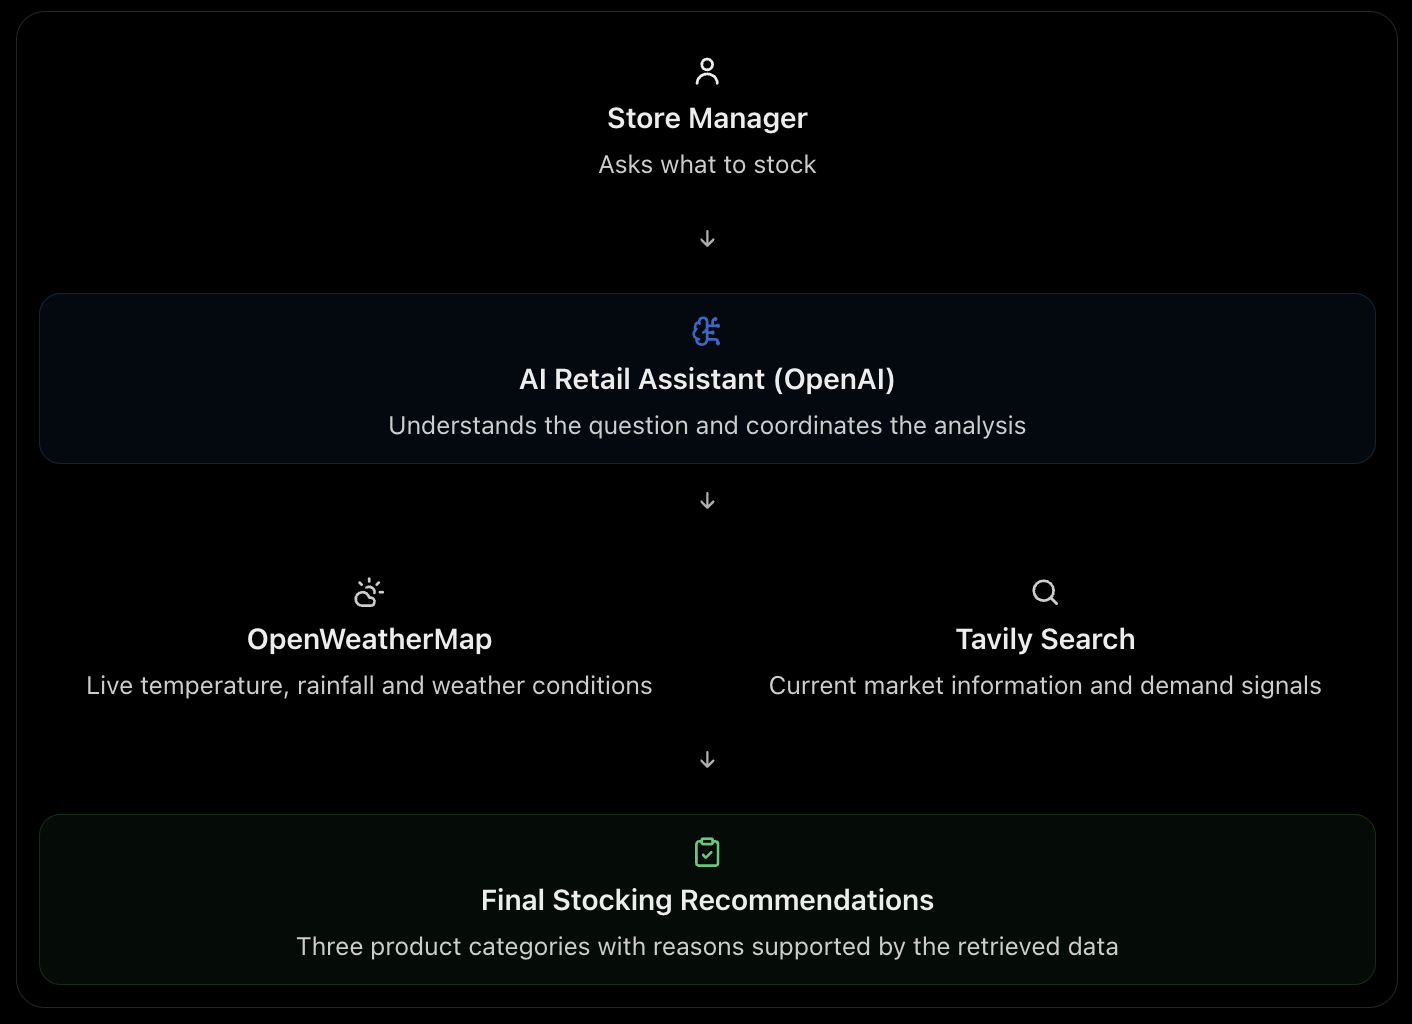

In [3]:
# What are we actually learning through this problem?
# It investigates three decisions.

# Decision 1 — REST API vs MCP
# We first build a REST-based AI assistant, where developers manually define tool descriptions and connect them to external APIs.
# Then we implement an MCP-based approach, where tools and their schemas are maintained on an MCP server.
# Question: If multiple AI assistants need the same tools, should we manage the integrations independently or use a standardised MCP interface?
# The notebook compares their design, execution latency, cost and tool reuse.

# Decision 2 — Python vs LangChain vs LangGraph
# Next, we solve the same store-manager problem using three approaches.
# a. Python-only: Can simple Python functions handle the entire process?
# b. LangChain: Can a framework simplify LLM and tool orchestration?
# c. LangGraph: Can a graph-based workflow provide better control of multiple steps and shared state?
# Question: Which approach is most suitable when the application must operate at enterprise scale?
# The notebook's scenario assumes 4,700 stores and more than 50,000 queries daily.

# Decision 3 — Build vs Buy
# Finally, the notebook examines whether Walmart should develop various AI components internally or use existing products and services.
# For example, should Walmart build its own LLM, purchase LLM inference through an API, or use an existing framework for orchestration?
# The notebook introduces a five-factor scoring model to make such choices more systematic.

In [4]:
# Problem Statement in one-paragraph:

# Imagine we are working for Walmart, where thousands of store managers need to make daily stocking decisions. Instead of manually checking weather conditions and market demand, we want to build an AI assistant that retrieves live information, analyses it, and recommends which products to stock. But our real engineering challenge is not simply making the AI answer a question. We need to decide how it connects with external systems, whether to use REST APIs or MCP, which framework to select among Python, LangChain and LangGraph, and which components to build ourselves versus purchase. Throughout this notebook, we will use the same Walmart retail example to compare these choices and arrive at a production architecture recommendation.

In [5]:
# Load the libraries and keys needed for the full notebook.
# This cell also defines the store we will use in every example.
import os
import json
import time
import requests
from typing import TypedDict
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv(override=True)

OPENAI_KEY  = os.getenv('OPENAI_API_KEY')
WEATHER_KEY = os.getenv('OPENWEATHERMAP_API_KEY')
TAVILY_KEY  = os.getenv('TAVILY_API_KEY')

client = OpenAI(api_key=OPENAI_KEY)

# Check whether all required API keys are present before we continue.
missing = [k for k, v in {
    'OPENAI_API_KEY':         OPENAI_KEY,
    'OPENWEATHERMAP_API_KEY': WEATHER_KEY,
    'TAVILY_API_KEY':         TAVILY_KEY,
}.items() if not v]

if missing:
    print(f'WARNING: Missing API keys: {missing}')
    print('Add them to your .env file before running this notebook.')
else:
    print('All required API keys loaded.')

# Fixed store context keeps every comparison in the notebook consistent.
STORE_ID   = 'WMT-2847'
STORE_CITY = 'Bengaluru'
print(f'Store context: {STORE_ID} | {STORE_CITY}, India')

All required API keys loaded.
Store context: WMT-2847 | Bengaluru, India


## The Decision Landscape

Every production AI system at Walmart scale requires three interlocking decisions made before any code is written:

1. **Protocol selection:** How should your AI agent communicate with external systems? REST API or Model Context Protocol (MCP)?
2. **Framework selection:** What orchestration layer do you build on? LangChain, LangGraph, or Python-only?
3. **Build vs Buy:** For each component, is it cheaper to build it or to buy a vendor solution?

Each decision compounds. A wrong protocol choice forces a framework rewrite downstream.

**The running scenario throughout this notebook:**

> *You are the AI engineer for the Walmart India Retail Assistant deployed at 4,700 stores with 50,000+ queries per day. The store manager at WMT-2847 in Bengaluru asks: "Based on today's actual conditions, what should we prioritise stocking today?"*

Every tool call in this notebook returns **live data** from real external APIs. The recommendation changes based on real weather and real market signals retrieved at runtime.

In [6]:
# # These helper functions are the live data layer used everywhere below.
# # One gets weather data and the other gets demand signals from search.
# def fetch_weather(city: str, country_code: str = 'IN') -> dict:
#     # Call the live OpenWeatherMap API for current weather.
#     url    = 'https://api.openweathermap.org/data/2.5/weather'
#     params = {'q': f'{city},{country_code}', 'appid': WEATHER_KEY, 'units': 'metric'} # units=metric gives Celsius, units=imperial gives Fahrenheit, units=standard gives Kelvin
#     resp   = requests.get(url, params=params, timeout=10)
#     resp.raise_for_status() # Raise an exception if the API call failed.
#     d = resp.json() # Parse the JSON response into a Python dictionary.
#     # Lets print the content of the response variable "d" to see what it contains
#     print("== Weather API Response ==")
#     print(json.dumps(d, indent=2))
#     print("=="*30)
#     return {
#         'city':           d['name'],
#         'country':        d['sys']['country'],
#         'temperature_c':  round(d['main']['temp'], 1),
#         'feels_like_c':   round(d['main']['feels_like'], 1),
#         'humidity_pct':   d['main']['humidity'],
#         'condition':      d['weather'][0]['description'],
#         'condition_main': d['weather'][0]['main'],
#         'wind_speed_ms':  d['wind']['speed'],
#         'pressure_hpa':   d['main']['pressure'],
#     }

# # Call the fetch_weather function to get the current weather for Bengaluru and print the result.
# # weather_data = fetch_weather("Mumbai", "IN")
# weather_data = fetch_weather("New York", "US")
# print(weather_data)

In [7]:
# def fetch_demand_trends(query: str, max_results: int = 3) -> dict:
#     # Call the live Tavily API for current market demand signals.
#     resp = requests.post(
#         'https://api.tavily.com/search',
#         json={
#             'api_key':        TAVILY_KEY,
#             'query':          query,
#             'max_results':    max_results,
#             'search_depth':   'basic',
#             'include_answer': True,
#         },
#         timeout=15,
#     )
#     resp.raise_for_status()
#     data = resp.json()
#     return {
#         'answer':  data.get('answer', ''),
#         'results': [
#             {'title': r['title'], 'content': r['content'][:350]}
#             for r in data.get('results', [])
#         ],
#     }

# # Call the fetch_demand_trends function to get the current market demand signals for "rainy season products" and print the result.
# demand_data = fetch_demand_trends("rainy season products", max_results=3)
# print(demand_data)    

In [8]:
# These helper functions are the live data layer used everywhere below.
# One gets weather data and the other gets demand signals from search.
def fetch_weather(city: str, country_code: str = 'IN') -> dict:
    # Call the live OpenWeatherMap API for current weather.
    url    = 'https://api.openweathermap.org/data/2.5/weather'
    params = {'q': f'{city},{country_code}', 'appid': WEATHER_KEY, 'units': 'metric'} # units=metric gives Celsius, units=imperial gives Fahrenheit, units=standard gives Kelvin
    resp   = requests.get(url, params=params, timeout=10)
    resp.raise_for_status() # Raise an exception if the API call failed.
    d = resp.json() # Parse the JSON response into a Python dictionary.
    # Lets print the content of the response variable "d" to see what it contains
    # print("== Weather API Response ==")
    # print(json.dumps(d, indent=2))
    # print("=="*30)
    return {
        'city':           d['name'],
        'country':        d['sys']['country'],
        'temperature_c':  round(d['main']['temp'], 1),
        'feels_like_c':   round(d['main']['feels_like'], 1),
        'humidity_pct':   d['main']['humidity'],
        'condition':      d['weather'][0]['description'],
        'condition_main': d['weather'][0]['main'],
        'wind_speed_ms':  d['wind']['speed'],
        'pressure_hpa':   d['main']['pressure'],
    }


def fetch_demand_trends(query: str, max_results: int = 3) -> dict:
    # Call the live Tavily API for current market demand signals.
    resp = requests.post(
        'https://api.tavily.com/search',
        json={
            'api_key':        TAVILY_KEY,
            'query':          query,
            'max_results':    max_results,
            'search_depth':   'basic',
            'include_answer': True,
        },
        timeout=15,
    )
    resp.raise_for_status()
    data = resp.json()
    return {
        'answer':  data.get('answer', ''),
        'results': [
            {'title': r['title'], 'content': r['content'][:350]}
            for r in data.get('results', [])
        ],
    }


# Quick live check so we know both external services are working.
print('Verifying live API connections...')
print()

live_weather = fetch_weather(STORE_CITY)
print(f'OpenWeatherMap -- {live_weather["city"]}, {live_weather["country"]}:')
print(f'  Temperature : {live_weather["temperature_c"]} C  (feels like {live_weather["feels_like_c"]} C)')
print(f'  Condition   : {live_weather["condition"]}')
print(f'  Humidity    : {live_weather["humidity_pct"]}%   Wind: {live_weather["wind_speed_ms"]} m/s')

print()
live_demand = fetch_demand_trends(f'retail grocery product demand {STORE_CITY} India')
print(f'Tavily Search -- query returned {len(live_demand["results"])} results:')
if live_demand['answer']:
    print(f'  Synthesised: {live_demand["answer"][:220]}...')
for r in live_demand['results'][:2]:
    print(f'  - {r["title"][:80]}')

Verifying live API connections...

OpenWeatherMap -- Bengaluru, IN:
  Temperature : 27.6 C  (feels like 29.8 C)
  Condition   : broken clouds
  Humidity    : 69%   Wind: 0.73 m/s

Tavily Search -- query returned 3 results:
  Synthesised: The sources indicate that Bengaluru's retail grocery market includes a variety of store formats such as supermarkets, hypermarkets, convenience stores, and gourmet stores, with a preference for product quality and freshn...
  - Emerging Growth Market…Bangalore India
  - Green India Retail - 2026 Company Profile & Competitors - Tracxn


## Section 1: REST API Integration -- Live External Services

In the REST pattern the developer manually writes a natural-language tool description and the AI uses that description to decide when and how to call the tool.

**Strengths:** Mature ecosystem, no new dependencies, works with any HTTP service.
**Weakness:** Tool schema lives in the developer's prompt. Schema drift and multi-agent reuse require copy-pasting descriptions across every agent that needs the tool.

The two tools below call **real external APIs** on every invocation:
- `get_store_weather` -- live call to OpenWeatherMap
- `search_demand_trends` -- live call to Tavily Search

In [9]:
# REST_TOOLS — Tell the AI which tools are available
# This cell shows the REST approach.
# The developer writes the tool schema by hand and the model uses it.
# REST tool schema -- developer writes this by hand for each agent that needs it
REST_TOOLS = [
    {
        'type': 'function',
        'function': {
            'name': 'get_store_weather',
            'description': (
                'Get real-time weather at a Walmart India store location. '
                'Use this to identify weather-driven demand: '
                'rain drives umbrella/raincoat/waterproof footwear sales, '
                'heat drives cold beverages/ice cream/sunscreen sales, '
                'cold drives hot beverages/heaters/blanket sales.'
            ),
            'parameters': {
                'type': 'object',
                'properties': {
                    'city':         {'type': 'string', 'description': 'City where the Walmart store is located'},
                    'country_code': {'type': 'string', 'description': 'ISO country code (default IN for India)'},
                },
                'required': ['city'],
            },
        },
    },
    {
        'type': 'function',
        'function': {
            'name': 'search_demand_trends',
            'description': (
                'Search for real-time retail product demand trends and market signals using Tavily. '
                'Use this to identify high-demand product categories based on current market conditions.'
            ),
            'parameters': {
                'type': 'object',
                'properties': {
                    'query':       {'type': 'string', 'description': 'Search query for demand or market signals'},
                    'max_results': {'type': 'integer', 'description': 'Number of results to return (1-5)'},
                },
                'required': ['query'],
            },
        },
    },
]


# execute_rest_tool() — Actually execute the tools
# name = "get_store_weather"
# args = {"city": "Bengaluru"}
def execute_rest_tool(name: str, args: dict) -> str:
    # Route each REST tool call to the matching Python function.
    if name == 'get_store_weather':
        result = fetch_weather(args['city'], args.get('country_code', 'IN'))
    elif name == 'search_demand_trends':
        result = fetch_demand_trends(args['query'], args.get('max_results', 3))
    else:
        result = {'error': f'Unknown tool: {name}'}
    return json.dumps(result)


# walmart_rest_agent() — Main AI assistant
def walmart_rest_agent(query: str) -> dict:
    # Run a full REST-style agent loop with live tool calls.
    start    = time.time()
    messages = [
        {
            'role': 'system',
            'content': (
                f'You are an AI assistant for Walmart India store {STORE_ID} in {STORE_CITY}. '
                'Use available tools to retrieve live data before making recommendations. '
                'Base your answer entirely on the real data returned by the tools.'
            ),
        },
        {'role': 'user', 'content': query},
    ]

    tools_called = [] # Keep track of which tools were called and with what arguments.
    total_in = total_out = 0

    # The agent loop — Let the model request tools repeatedly until it has enough information to answer the user query.
    # Keep calling the model until it stops asking for tools.
    for _ in range(6):
        resp = client.chat.completions.create(
            model='gpt-4o', messages=messages, tools=REST_TOOLS,
            tool_choice='auto', temperature=0, max_tokens=500,
        )
        total_in  += resp.usage.prompt_tokens
        total_out += resp.usage.completion_tokens
        msg = resp.choices[0].message

        if not msg.tool_calls:
            final_answer = msg.content.strip()
            break

        messages.append(msg)
        for tc in msg.tool_calls:
            args   = json.loads(tc.function.arguments)
            result = execute_rest_tool(tc.function.name, args)
            tools_called.append({'tool': tc.function.name, 'args': args})
            messages.append({'role': 'tool', 'tool_call_id': tc.id, 'content': result})

    latency = time.time() - start
    cost    = (total_in * 2.5 + total_out * 10.00) / 1_000_000
    return {
        'answer':       final_answer,
        'tools_called': tools_called,
        'latency_sec':  round(latency, 2),
        'cost_usd':     round(cost, 6),
        'tokens_in':    total_in,
        'tokens_out':   total_out,
        'protocol':     'REST',
    }

In [10]:
# Ask the REST agent the main Walmart store question and inspect the result.
STORE_QUERY = (
    f'I am the store manager at {STORE_ID} in {STORE_CITY}. '
    "Based on today's actual weather conditions and current market demand signals, "
    'give me 3 specific product categories I should prioritise stocking today. '
    'For each category, explain why the live data supports this recommendation.'
)

print(f'Query: {STORE_QUERY}')
print()

rest_result = walmart_rest_agent(STORE_QUERY)

# Show which tools were used before we read the final answer.
print('Tools called by the REST agent:')
for t in rest_result['tools_called']:
    print(f'  {t["tool"]}({json.dumps(t["args"])})')

print()
print('REST Agent Answer (based on live data):')
print('-' * 70)
print(rest_result['answer'])
print('-' * 70)
print(f'Latency : {rest_result["latency_sec"]}s')
print(f'Cost    : ${rest_result["cost_usd"]}')
print(f'Protocol: REST (hand-written tool schema)')

Query: I am the store manager at WMT-2847 in Bengaluru. Based on today's actual weather conditions and current market demand signals, give me 3 specific product categories I should prioritise stocking today. For each category, explain why the live data supports this recommendation.

Tools called by the REST agent:
  get_store_weather({"city": "Bengaluru", "country_code": "IN"})
  search_demand_trends({"query": "India", "max_results": 3})

REST Agent Answer (based on live data):
----------------------------------------------------------------------
Based on today's weather conditions in Bengaluru and current market demand signals, here are three product categories you should prioritize stocking at the store:

1. **Cold Beverages and Ice Cream:**
   - **Weather Justification:** The current temperature in Bengaluru is 27.6°C, with a "feels like" temperature of 29.8°C and 69% humidity. These warm and humid conditions typically drive demand for cold beverages and ice cream as customers look

## Section 2: Model Context Protocol (MCP) -- Real FastMCP Server

MCP (Anthropic, 2024) separates tool definition from tool calling.
The MCP server owns the schema. Any MCP-compatible AI client connects, discovers tools automatically, and calls them -- without the developer writing a single word of tool description.

**Architecture:**
```
AI Host (GPT-4o-mini)  <-->  MCP Client (test_client)  <-->  FastMCP Server  <-->  Live External APIs
```

**What changes vs REST:**
- Tool descriptions live on the **server**, not in developer prompts
- Schema is **machine-readable** JSON -- no natural language required
- Any number of AI clients can point at the same server without duplicating schema
- The server handles versioning; clients auto-discover changes on reconnect

**What stays the same:**
- Underlying HTTP calls to OpenWeatherMap and Tavily are identical
- OpenAI token cost per call is the same
- MCP adds a schema-fetch round-trip on first connection (~5ms)

The FastMCP server below uses real API calls inside every registered tool.

In [11]:
# 1. First, what is the problem with REST APIs?

# Imagine Walmart has 20 AI agents:
# - Inventory Agent
# - Sales Agent
# - Customer Support Agent
# - Procurement Agent
# All these agents need weather data, sales information and inventory data.

# In our previous REST-style code, we manually wrote the tool definitions and the Python logic to execute them.

# The problem: If 20 agents need the same tool, developers may end up repeating and maintaining similar integration code in many places.

| REST-style agent integrations | Challenge                                             |
| ----------------------------- | ----------------------------------------------------- |
| Manual tool definitions       | Developers write schemas for each agent               |
| Repeated integration code     | Multiple agents may duplicate work                    |
| Maintenance                   | Changes may require updates across agents             |
| Tool discovery                | Tools are often manually registered                   |
| Scaling                       | More agents and tools increase integration complexity |

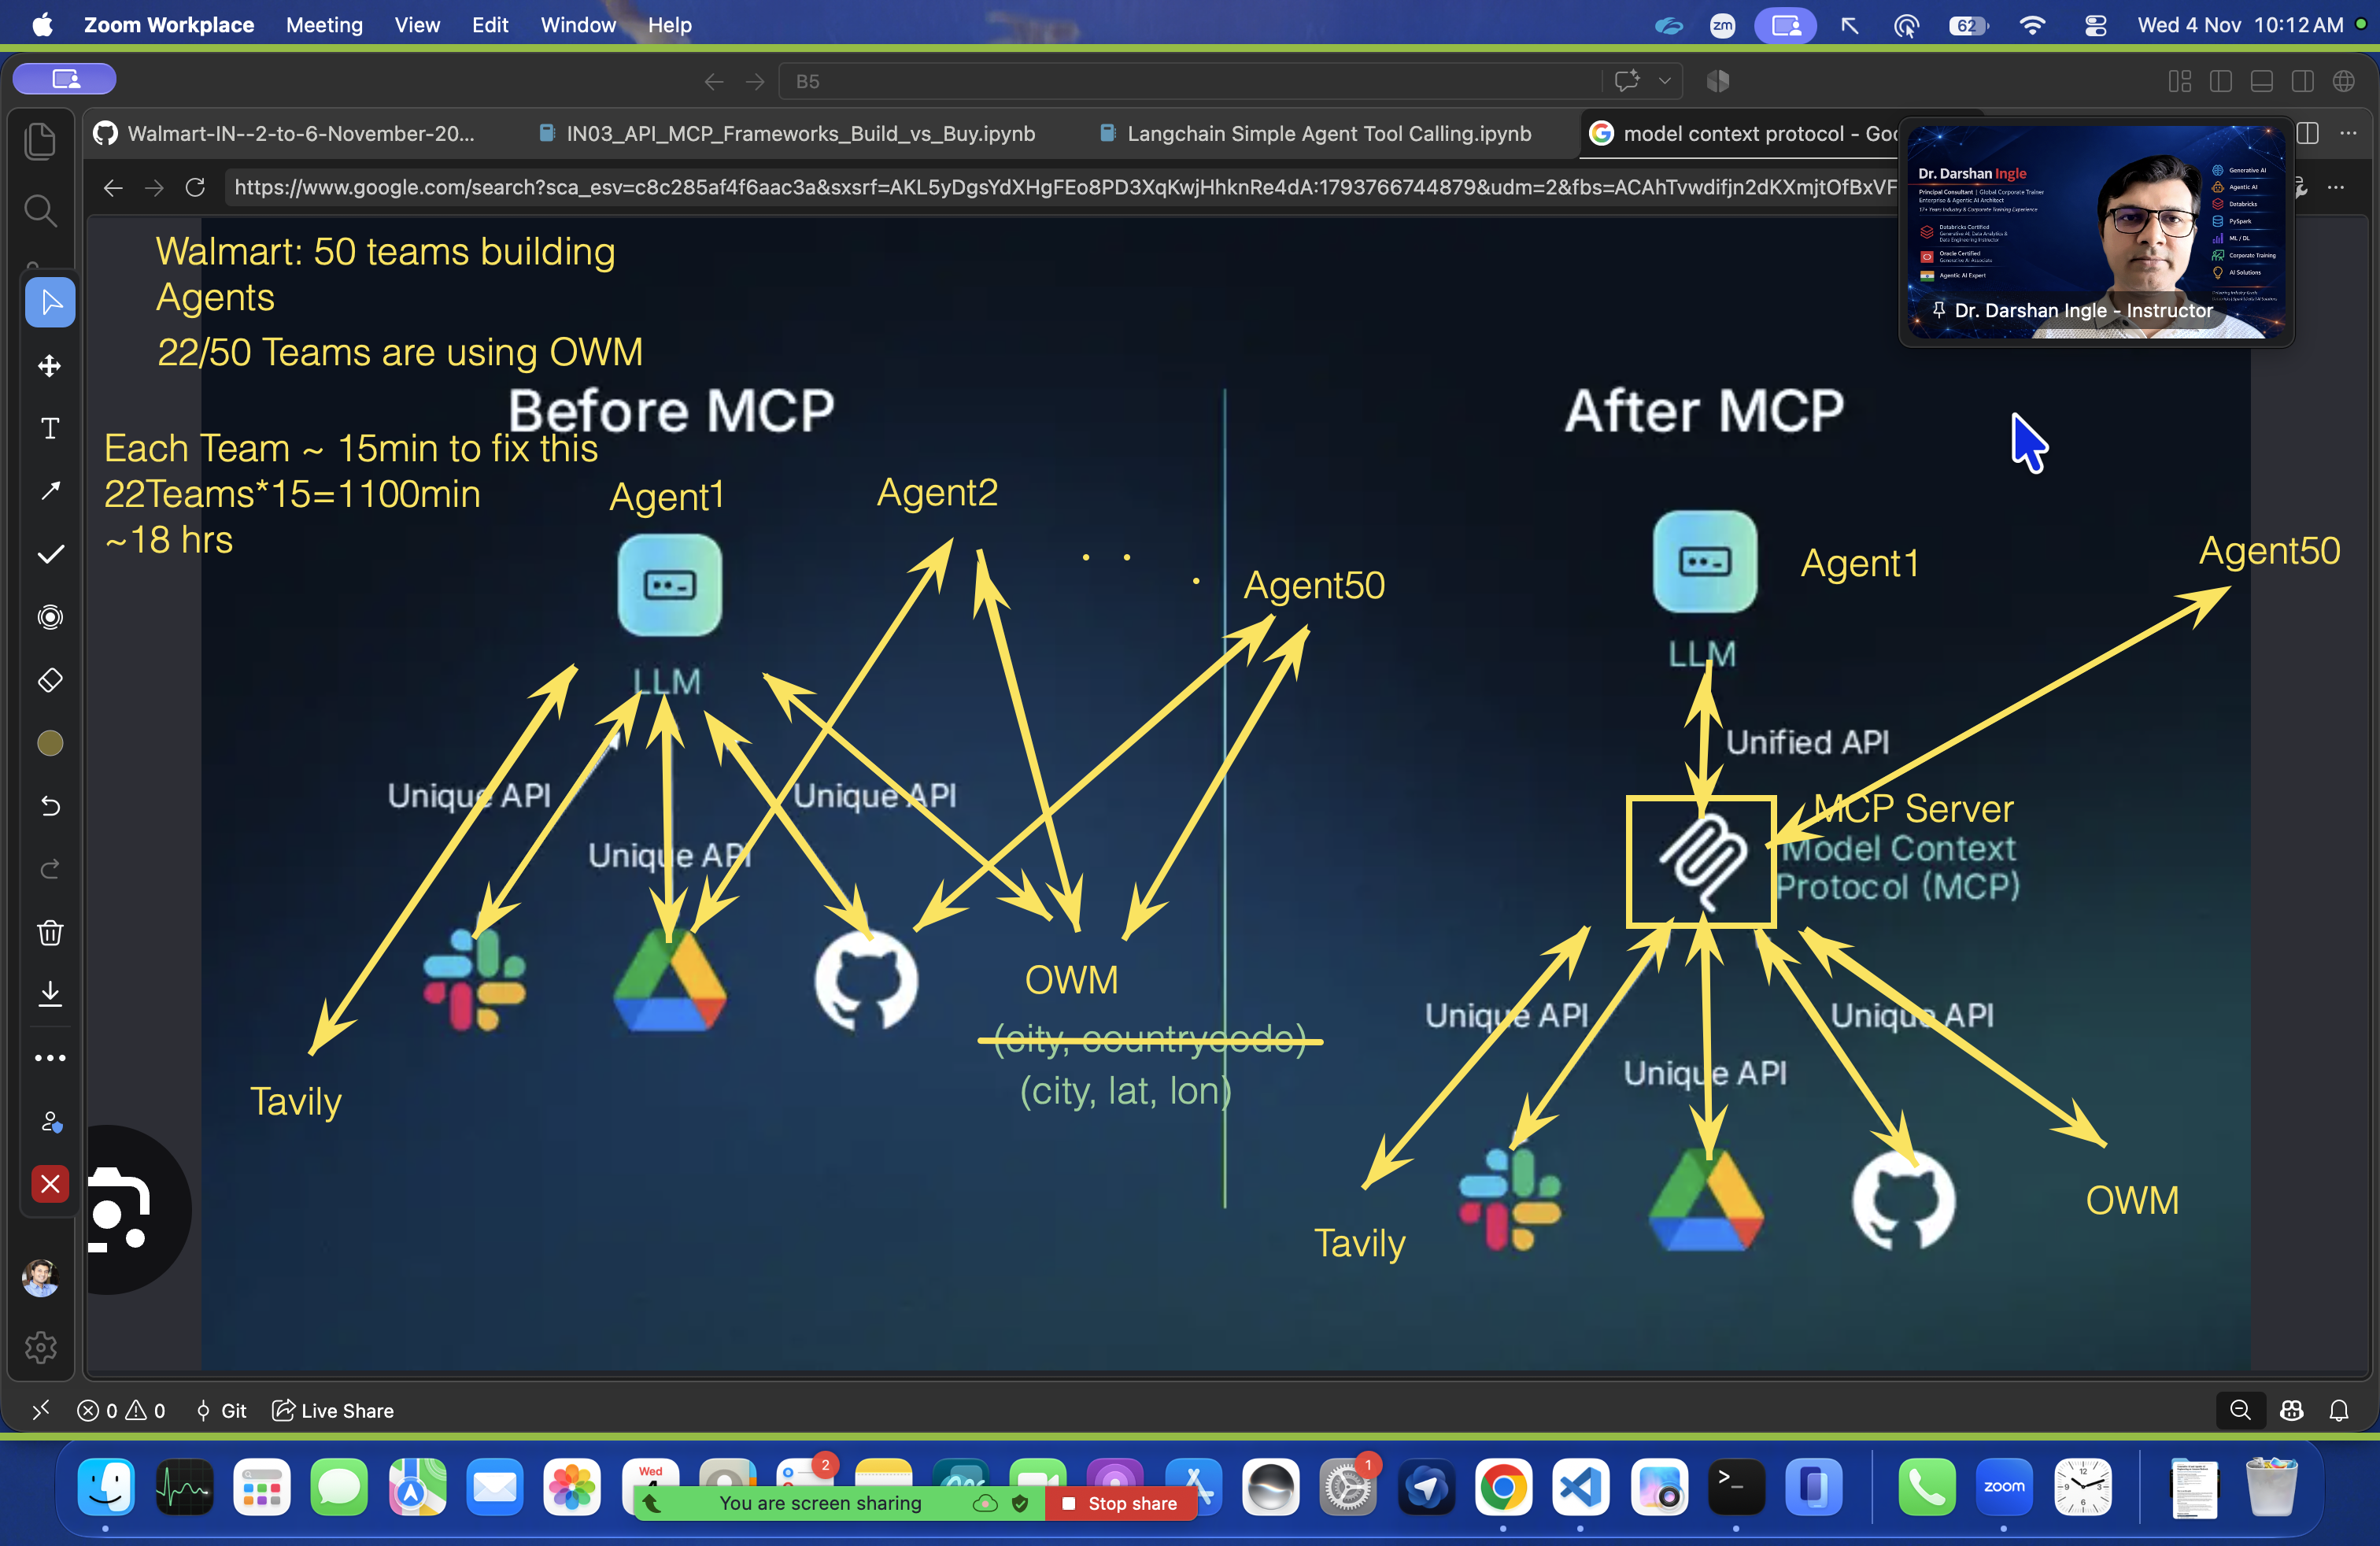

In [12]:
# REST APIs themselves are not bad. They are widely used and reliable. The difficulty is connecting many AI agents to many different tools in a standardised way.

In [13]:
# 2. What is MCP?
# MCP stands for Model Context Protocol.

# It is an open standard introduced by Anthropic in November 2024.

# MCP provides a standard way for AI applications to connect with external tools, data sources and services.

# Think of MCP as a USB-C port for AI applications.

# Before USB-C, devices often required different connectors. With a common standard, connecting compatible devices becomes easier.

# Similarly, MCP allows AI applications to interact with different tools through a common protocol.

In [14]:
# What are MCP Host, Client and Server?

# 1. MCP Host
# The main AI application where the user interacts with the AI agent. It sends requests to the MCP Server and receives responses.
# eg: Walmart AI Retail Assistant

# 2. MCP Client
# The connector inside the host that communicates using MCP protocol.
# eg: Component connecting the assistant to the weather MCP server

# 3. MCP Server
# Exposes tools and data to MCP clients.
# eg: Server offering get_store_weather

### MCP architecture

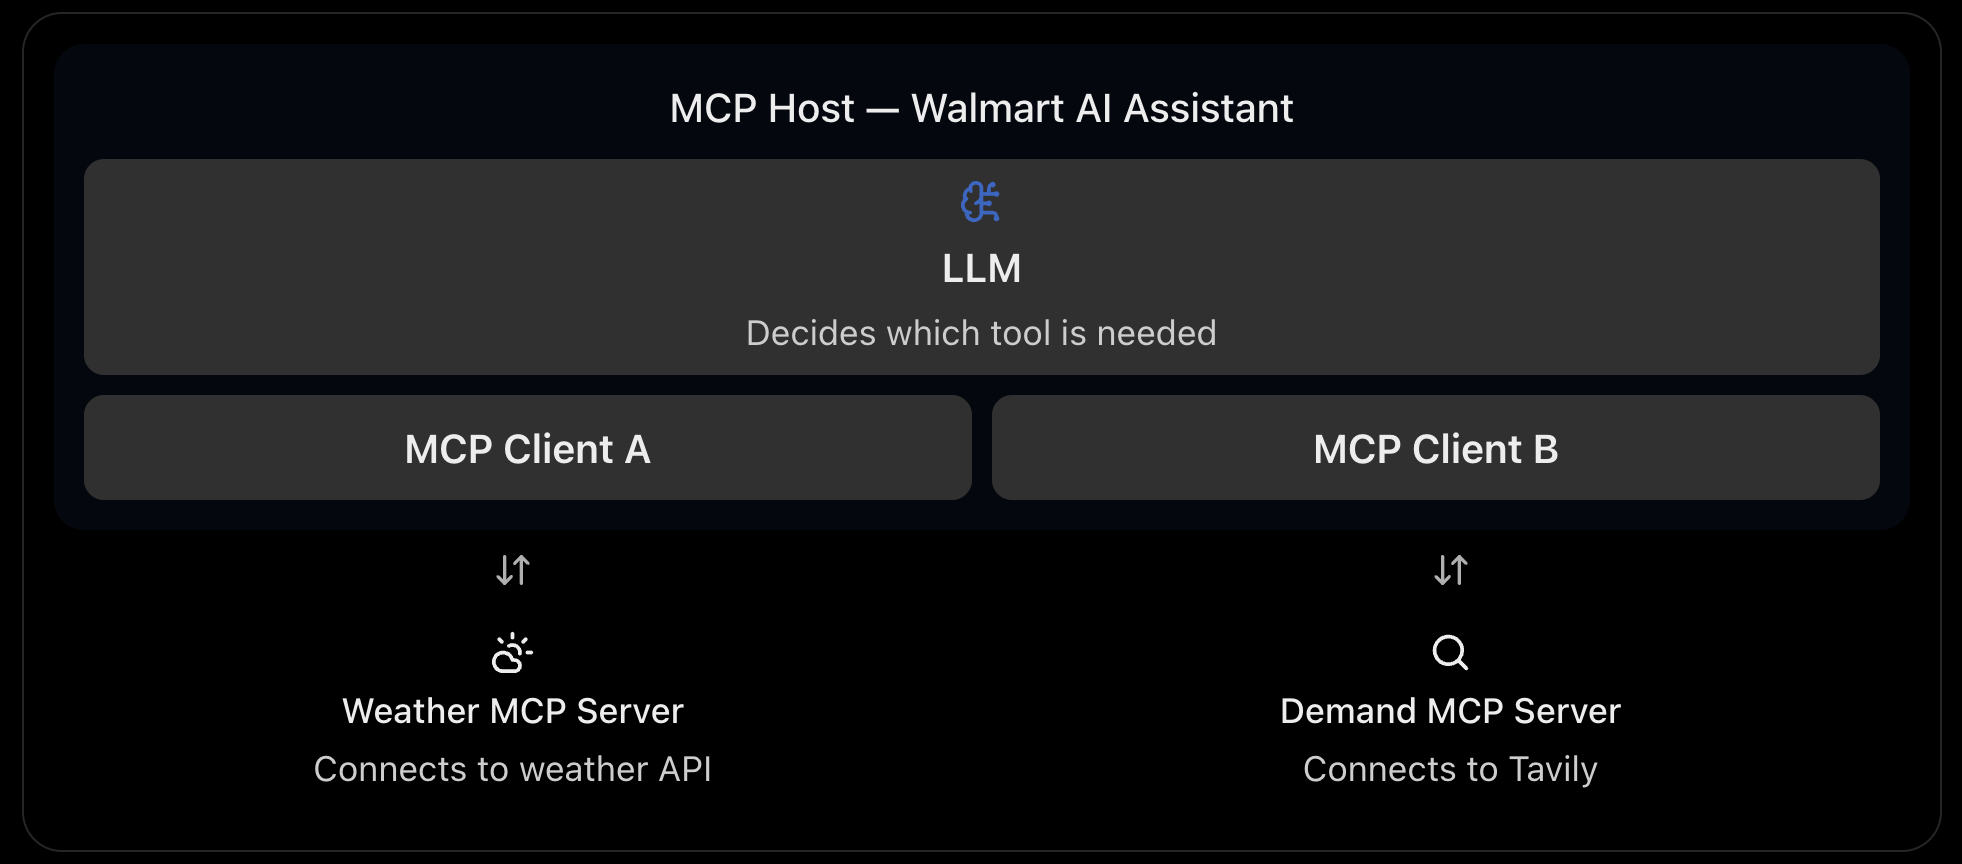

In [15]:
# One MCP host can contain multiple MCP clients, typically one for each server connection.

In [16]:
# Suppose the Walmart manager asks, "What should I stock today?"
# 1. Host: Receives the question.
# 2. Client: Connects to the MCP server and discovers available tools.
# 3. Server: Advertises tools such as get_store_weather.
# 4. LLM: Decides that weather information is required.
# 5. Client: Sends the tool request to the server.
# 6. Server: Calls the weather API and returns the result.
# 7. Host: Gives the result to the LLM, which prepares its recommendation.

| REST-style approach in our notebook              | MCP approach                                      |
| ------------------------------------------------ | ------------------------------------------------- |
| Tool schemas manually supplied to each agent     | Server advertises tool schemas                    |
| Custom Python tool dispatcher                    | Standard MCP tool invocation                      |
| Integration may be duplicated across agents      | One server can be reused by multiple applications |
| Changes may require updates to individual agents | Tool interface can be maintained centrally        |
| Simple for a few integrations                    | Useful for shared, growing tool ecosystems        |

In [17]:
# In this code, we create a Walmart MCP server and register three tools.

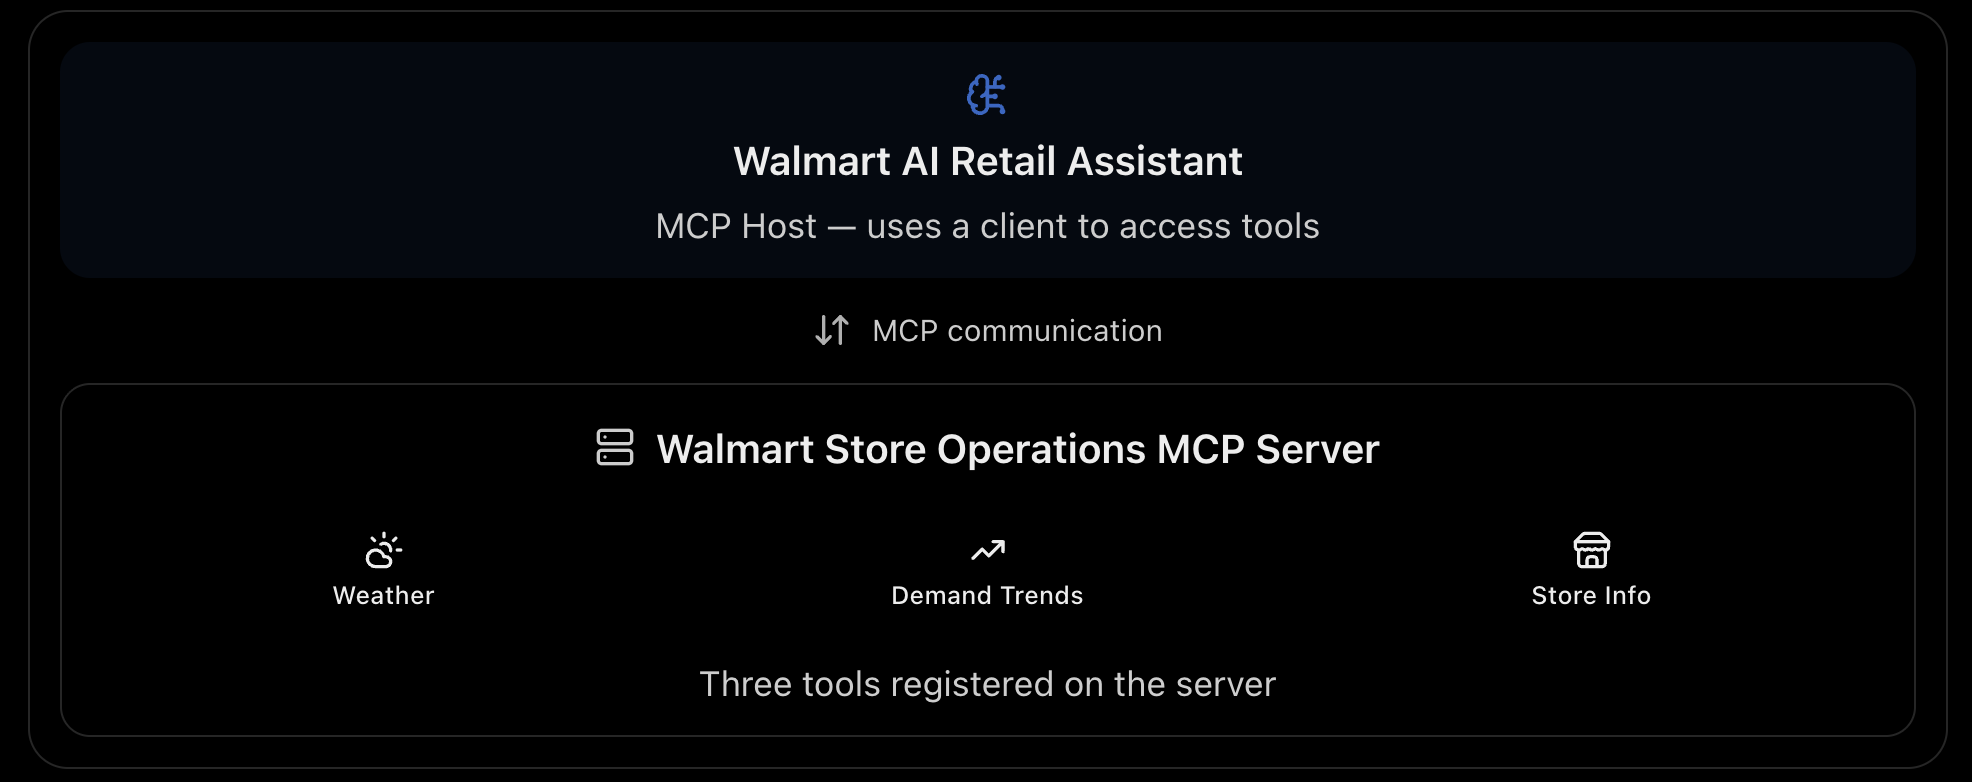

In [18]:
# %pip install mcp --break-system-packages -q

In [19]:
# This cell sets up the FastMCP server and registers its tools.
# The main idea is that tool definitions live on the server side.
MCP_AVAILABLE = False

try:
    import inspect
     # from mcp.server.fastmcp import FastMCP
    from mcp.server.mcpserver import MCPServer

    # This helps async-friendly packages behave inside Jupyter.
    try:
        import nest_asyncio
        nest_asyncio.apply()
    except ImportError:
        pass

    # walmart_mcp = FastMCP(
    #     'walmart-store-ops',
    #     instructions=(
    #         'Walmart India Store Operations MCP Server. '
    #         'Exposes real-time weather intelligence and market demand signals '
    #         'for store management decisions at WMT stores across India.'
    #     ),
    # )

    walmart_mcp = MCPServer(
        'walmart-store-ops',
        instructions=(
            'Walmart India Store Operations MCP Server. '
            'Exposes real-time weather intelligence and market demand signals '
            'for store management decisions at WMT stores across India.'
        ),
    )

    @walmart_mcp.tool()
    def get_store_weather(city: str, country_code: str = 'IN') -> dict:
        """Get current weather at a Walmart India store location for demand planning."""
        return fetch_weather(city, country_code)

    @walmart_mcp.tool()
    def search_demand_trends(query: str, max_results: int = 3) -> dict:
        """Search live retail demand trends and market signals for store planning."""
        return fetch_demand_trends(query, max_results)

    @walmart_mcp.tool()
    def get_store_info(store_id: str) -> dict:
        """Retrieve operational metadata for a Walmart India store."""
        registry = {
            'WMT-2847': {'location': 'Bengaluru, Karnataka', 'format': 'Supercenter',
                         'departments': 32, 'daily_queries': 1200, 'region': 'South India'},
            'WMT-1023': {'location': 'Mumbai, Maharashtra',  'format': 'Supercenter',
                         'departments': 28, 'daily_queries': 1800, 'region': 'West India'},
            'WMT-0511': {'location': 'Delhi NCR',            'format': 'Supercenter',
                         'departments': 35, 'daily_queries': 2100, 'region': 'North India'},
            'WMT-3302': {'location': 'Hyderabad, Telangana', 'format': 'Neighborhood Market',
                         'departments': 18, 'daily_queries':  620, 'region': 'South India'},
        }
        return registry.get(store_id, {'error': f'Store {store_id} not found in registry'})

    def _annotation_to_json_type(annotation) -> str:
        # Convert Python type hints into simple JSON schema types.
        return {
            str: 'string',
            int: 'integer',
            float: 'number',
            bool: 'boolean',
            dict: 'object',
            list: 'array',
        }.get(annotation, 'string')

    def _build_mcp_tool_entry(func) -> dict:
        # Build a small machine-readable schema for each MCP tool.
        sig = inspect.signature(func)
        properties = {}
        required = []

        for param_name, param in sig.parameters.items():
            if param.kind not in (inspect.Parameter.POSITIONAL_OR_KEYWORD, inspect.Parameter.KEYWORD_ONLY):
                continue

            prop = {'type': _annotation_to_json_type(param.annotation)}
            if param.default is not inspect._empty:
                prop['default'] = param.default
            else:
                required.append(param_name)
            properties[param_name] = prop

        return {
            'name': func.__name__,
            'description': inspect.getdoc(func) or '',
            'inputSchema': {
                'type': 'object',
                'properties': properties,
                'required': required,
            },
            'handler': func,
        }

    # Keep the registered MCP tools in one place for easy lookup below.
    MCP_TOOL_REGISTRY = {
        tool['name']: tool
        for tool in [
            _build_mcp_tool_entry(get_store_weather),
            _build_mcp_tool_entry(search_demand_trends),
            _build_mcp_tool_entry(get_store_info),
        ]
    }

    def call_mcp_tool(name: str, args: dict) -> dict:
        # Run an MCP tool by name using the saved registry entry.
        return MCP_TOOL_REGISTRY[name]['handler'](**args)

    MCP_AVAILABLE = True
    print(f'FastMCP server created: {walmart_mcp.name}')
    print()
    print('Tools registered on the MCP server:')
    print('  - get_store_weather    (live data: OpenWeatherMap API)')
    print('  - search_demand_trends (live data: Tavily Search API)')
    print('  - get_store_info       (store registry -- note: 3 tools vs 2 for REST)')
    print()
    print('Key difference from REST: tool descriptions live here on the server,')
    print('not in the developer\'s agent code. Any MCP client discovers them automatically.')

except ImportError as e:
    print(f'mcp package not installed: {e}')
    print('Install: pip install mcp --break-system-packages')
    print()
    print('The REST section above is fully functional without this package.')
    print('FastMCP cells below will be skipped gracefully.')

FastMCP server created: walmart-store-ops

Tools registered on the MCP server:
  - get_store_weather    (live data: OpenWeatherMap API)
  - search_demand_trends (live data: Tavily Search API)
  - get_store_info       (store registry -- note: 3 tools vs 2 for REST)

Key difference from REST: tool descriptions live here on the server,
not in the developer's agent code. Any MCP client discovers them automatically.


In [20]:
# Now combine MCP tool schemas, MCP tool execution, and the LLM in one loop.
# This mirrors the REST agent flow, but the tool schema comes from the server side.
# Step 3: Full MCP Agent -- schema from server registry, tool execution from MCP server definitions

if MCP_AVAILABLE:
    def walmart_mcp_agent(query: str) -> dict:
        # Run a full MCP-style agent loop using the server-owned schema.
        start = time.time()

        openai_tools = [
            {
                'type': 'function',
                'function': {
                    'name':        t['name'],
                    'description': t['description'],
                    'parameters':  t['inputSchema'],
                },
            }
            for t in MCP_TOOL_REGISTRY.values()
        ]

        messages = [
            {
                'role': 'system',
                'content': (
                    f'You are an AI assistant for Walmart India store {STORE_ID} in {STORE_CITY}. '
                    'Tools are provided by the Walmart MCP server. '
                    'Use all relevant tools to give a complete, data-driven recommendation.'
                ),
            },
            {'role': 'user', 'content': query},
        ]

        tools_called = []
        total_in = total_out = 0
        final_answer = ''

        # Keep going until the model stops asking for tool calls.
        for _ in range(6):
            resp = client.chat.completions.create(
                model='gpt-4o-mini', messages=messages, tools=openai_tools,
                tool_choice='auto', temperature=0, max_tokens=500,
            )
            total_in  += resp.usage.prompt_tokens
            total_out += resp.usage.completion_tokens
            msg = resp.choices[0].message

            if not msg.tool_calls:
                final_answer = msg.content.strip()
                break

            messages.append(msg)

            for tc in msg.tool_calls:
                args   = json.loads(tc.function.arguments)
                result = call_mcp_tool(tc.function.name, args)
                tools_called.append({'tool': tc.function.name, 'args': args})
                messages.append({
                    'role':         'tool',
                    'tool_call_id': tc.id,
                    'content':      json.dumps(result),
                })

        latency = time.time() - start
        cost    = (total_in * 2.5 + total_out * 10.00) / 1_000_000
        return {
            'answer':       final_answer,
            'tools_called': tools_called,
            'latency_sec':  round(latency, 2),
            'cost_usd':     round(cost, 6),
            'tokens_in':    total_in,
            'tokens_out':   total_out,
            'protocol':     'MCP',
        }

    mcp_result = walmart_mcp_agent(STORE_QUERY)

    print('Tools called via MCP protocol:')
    for t in mcp_result['tools_called']:
        print(f'  {t["tool"]}({json.dumps(t["args"])})')
    print()
    print('MCP Agent Answer (based on live data):')
    print('-' * 70)
    print(mcp_result['answer'])
    print('-' * 70)
    print(f'Latency : {mcp_result["latency_sec"]}s')
    print(f'Cost    : ${mcp_result["cost_usd"]}')
    print(f'Protocol: MCP (schema auto-discovered from FastMCP server)')

else:
    mcp_result = {**rest_result, 'protocol': 'MCP (fallback -- install mcp package)'}
    print('mcp package not installed. Showing REST result as reference.')
    print(f'Answer: {mcp_result["answer"][:300]}...')

[11/04/26 10:54:20] INFO     HTTP Request: POST https://api.openai.com/v1/chat/completions          ]8;id=465554;file:///opt/homebrew/lib/python3.11/site-packages/httpx/_client.py\_client.py]8;;\:]8;id=564211;file:///opt/homebrew/lib/python3.11/site-packages/httpx/_client.py#1025\1025]8;;\
                             "HTTP/1.1 200 OK"                                                                     

[11/04/26 10:54:22] INFO     HTTP Request: POST https://api.openai.com/v1/chat/completions          ]8;id=552865;file:///opt/homebrew/lib/python3.11/site-packages/httpx/_client.py\_client.py]8;;\:]8;id=41964;file:///opt/homebrew/lib/python3.11/site-packages/httpx/_client.py#1025\1025]8;;\
                             "HTTP/1.1 200 OK"                                                                     

[11/04/26 10:54:26] INFO     HTTP Request: POST https://api.openai.com/v1/chat/completions          ]8;id=287150;file:///opt/homebrew/lib/python3.11/site-packages/httpx/_client.py\_client.py]8;;\:]8;id=532423;file:///opt/homebrew/lib/python3.11/site-packages/httpx/_client.py#1025\1025]8;;\
                             "HTTP/1.1 200 OK"                                                                     

Tools called via MCP protocol:
  get_store_weather({"city": "Bengaluru"})
  search_demand_trends({"query": "Bengaluru", "max_results": 3})
  search_demand_trends({"query": "weather", "max_results": 3})

MCP Agent Answer (based on live data):
----------------------------------------------------------------------
Based on the current weather conditions in Bengaluru and the latest market demand signals, here are three specific product categories you should prioritize stocking today:

### 1. **Beverages (Cold Drinks and Juices)**
- **Weather Insight**: The temperature is currently around 27.6°C with high humidity (69%). Such weather conditions often lead to increased demand for refreshing beverages.
- **Market Demand Signal**: Given the warm and humid climate, consumers are likely to seek out cold drinks and juices to stay hydrated. This aligns with typical consumer behavior during similar weather patterns.

### 2. **Snacks (Chips, Nuts, and Ready-to-Eat Items)**
- **Weather Insight**: The

In [21]:
STORE_QUERY

"I am the store manager at WMT-2847 in Bengaluru. Based on today's actual weather conditions and current market demand signals, give me 3 specific product categories I should prioritise stocking today. For each category, explain why the live data supports this recommendation."

## Section 3: Framework Selection -- LangChain vs LangGraph vs Python-only

Framework selection is a TCO (Total Cost of Ownership) decision, not a features decision.
Every framework adds capabilities and adds cost: dependency risk, debugging complexity, version lock, and team learning curve.

All three implementations below use the **same real live data** (OpenWeatherMap + Tavily).
The difference is in how each framework manages state, control flow, and observability.

In [22]:
# Imagine the Walmart store manager in Bengaluru asks:
#     "Based on today's weather and market trends, which three product categories should we prioritise stocking?"

# Our Python program will automatically fetch the weather and market data first, give that information to GPT-4o, and ask it to recommend the products.

# The key difference: The developer decides which data to fetch and in what order. The LLM does not decide which tools to call.

In [23]:
# This version uses plain Python only: no tool framework, no graph, just direct calls.
# It is the simplest option, but the developer must control every step manually.
def python_only_agent(query: str) -> dict:
    # Python-only: full control, minimum abstraction.
    # Developer manually fetches data before the LLM call -- no dynamic tool calling.
    start = time.time()

    weather = fetch_weather(STORE_CITY)
    demand  = fetch_demand_trends(f'retail product demand {STORE_CITY} India', max_results=2)

    context = (
        f'Live weather for {STORE_CITY}: {json.dumps(weather)}. '
        f'Market demand signals: {demand["answer"][:400]}'
    )

    resp = client.chat.completions.create(
        model='gpt-4o',
        messages=[
            {
                'role': 'system',
                'content': (
                    f'You are an AI assistant for Walmart India store {STORE_ID} in {STORE_CITY}. '
                    f'Current live data: {context}'
                ),
            },
            {'role': 'user', 'content': query},
        ],
        temperature=0, max_tokens=400,
    )

    latency = time.time() - start
    ti, to  = resp.usage.prompt_tokens, resp.usage.completion_tokens
    return {
        'answer':      resp.choices[0].message.content.strip(),
        'latency_sec': round(latency, 2),
        'cost_usd':    round((ti * 0.15 + to * 0.60) / 1_000_000, 6),
        'framework':   'Python-only',
        'data_fetch':  'Manual pre-fetch (LLM cannot request more data dynamically)',
        'loc_approx':  30,
    }

py_result = python_only_agent(STORE_QUERY)
print('Python-only Agent Answer:')
print('-' * 60)
print(py_result['answer'][:450])
print('-' * 60)
print(f'Latency: {py_result["latency_sec"]}s | Framework: Python-only')
print(f'Note   : {py_result["data_fetch"]}')

[11/04/26 10:54:29] INFO     HTTP Request: POST https://api.openai.com/v1/chat/completions          ]8;id=660673;file:///opt/homebrew/lib/python3.11/site-packages/httpx/_client.py\_client.py]8;;\:]8;id=521856;file:///opt/homebrew/lib/python3.11/site-packages/httpx/_client.py#1025\1025]8;;\
                             "HTTP/1.1 200 OK"                                                                     

Python-only Agent Answer:
------------------------------------------------------------
Based on today's weather conditions and current market demand signals, here are three specific product categories you should prioritize stocking at WMT-2847 in Bengaluru:

1. **Rain Gear and Accessories:**
   - **Reasoning:** The current weather condition in Bengaluru is "broken clouds" with a high humidity level of 69%. This suggests a possibility of rain or at least a damp environment. Stocking up on rain gear such as umbrellas, raincoats, and 
------------------------------------------------------------
Latency: 2.86s | Framework: Python-only
Note   : Manual pre-fetch (LLM cannot request more data dynamically)


In [24]:
# This approach is simple, predictable, and relatively easy to debug. It works well when our business workflow is straightforward.

# But imagine Walmart wants an assistant that can dynamically decide whether it needs weather, sales history, supplier information, or inventory information depending on the manager's question.
# Managing those decisions manually would make the Python code more complicated.

# That is why we will next explore frameworks such as LangChain and LangGraph, which help organise tool-using and multi-step AI workflows.

In [25]:
# %pip install langchain langchain-openai -q

In [26]:
# This version uses LangChain to manage tools and the agent loop for us.
# It reduces boilerplate, but adds another abstraction layer to learn and debug.
LC_AVAILABLE = False
lc_latency   = None

try:
    from langchain_openai import ChatOpenAI # LLM / Brain
    from langchain_core.prompts import ChatPromptTemplate # Prompt/Ears
    from langchain_core.tools import tool # Hands
    from langchain.agents import create_tool_calling_agent, AgentExecutor
    # create_tool_calling_agent - Combining LLM+Prompt+Tools
    # AgentExecutor - Running everything

    @tool
    def lc_get_weather(city: str) -> str:
        """Get real-time weather at a Walmart India store location for demand planning."""
        return json.dumps(fetch_weather(city))

    @tool
    def lc_search_trends(query: str) -> str:
        """Search for real-time retail demand trends and market signals using Tavily."""
        return json.dumps(fetch_demand_trends(query, max_results=2))

    lc_llm   = ChatOpenAI(model='gpt-4o', temperature=0)
    lc_tools = [lc_get_weather, lc_search_trends]

    lc_prompt = ChatPromptTemplate.from_messages([
        ('system',
         f'You are an AI assistant for Walmart India store {STORE_ID} in {STORE_CITY}. '
         'Use tools to retrieve live data before making recommendations.'),
        ('human', '{input}'),
        ('placeholder', '{agent_scratchpad}'),
    ])

    lc_agent    = create_tool_calling_agent(lc_llm, lc_tools, lc_prompt)
    lc_executor = AgentExecutor(agent=lc_agent, tools=lc_tools, verbose=False, max_iterations=6)

    start       = time.time()
    lc_response = lc_executor.invoke({'input': STORE_QUERY})
    # lc_response = lc_executor.invoke({'input': "What is the current date and time in India?"})
    lc_latency  = time.time() - start

    print('LangChain Agent Answer (real tools via LCEL + AgentExecutor):')
    print('-' * 60)
    print(lc_response['output'][:450])
    print('-' * 60)
    print(f'Latency: {lc_latency:.2f}s | Framework: LangChain')
    LC_AVAILABLE = True

except ImportError as e:
    print(f'LangChain not installed: {e}')
    print('Install: pip install langchain langchain-openai --break-system-packages')

LangChain not installed: No module named 'langchain_core.memory'
Install: pip install langchain langchain-openai --break-system-packages


In [27]:
STORE_QUERY

"I am the store manager at WMT-2847 in Bengaluru. Based on today's actual weather conditions and current market demand signals, give me 3 specific product categories I should prioritise stocking today. For each category, explain why the live data supports this recommendation."

In [28]:
# %pip install langgraph -q

In [32]:
# This version uses LangGraph, which is built for step-by-step workflows with shared state.
# It is more verbose than LangChain, but it makes control flow easier to see.
LG_AVAILABLE = False
lg_latency   = None


# Example:
# {
# query: ""
# weather_data: {}
# demand_data: {}
# answer: ""
# route: ""     
# }
try:
    from langgraph.graph import StateGraph, END

    class WalmartState(TypedDict):
        # Shared state passed from one graph step to the next.
        query:        str
        weather_data: dict
        demand_data:  dict
        answer:       str
        route:        str



#     {
# query: "I am the store manager at WMT-2847..."
# weather_data: {}
# demand_data: {}
# answer: ""
# route: ""     
# }
    def classify_node(state: WalmartState) -> WalmartState:
        # Decide whether the query needs weather only, demand only, or both.
        q = state['query'].lower() # q = "i am the store manager at wmt-2847..."
        if any(w in q for w in ['weather', 'rain', 'temperature', 'heat', 'cold', 'wind', 'humid']):
            state['route'] = 'weather_only'
        elif any(w in q for w in ['trend', 'demand', 'market', 'popular', 'sell', 'sales']):
            state['route'] = 'demand_only'
        else:
            state['route'] = 'full_analysis'
        return state
#     {
# query: "I am the store manager at WMT-2847..."
# weather_data: {}
# demand_data: {}
# answer: ""
# route: "full_analysis"     
# }

#     {
# query: "I am the store manager at WMT-2847..."
# weather_data: {}
# demand_data: {}
# answer: ""
# route: "full_analysis"     
# }
    def weather_node(state: WalmartState) -> WalmartState:
        # Fetch weather and save it in the shared workflow state.
        state['weather_data'] = fetch_weather(STORE_CITY)
        return state
#     {
# query: "I am the store manager at WMT-2847..."
# weather_data: {"temperature": 25, "humidity": 60}
# demand_data: {}
# answer: ""
# route: "full_analysis"     
# }

#     {
# query: "I am the store manager at WMT-2847..."
# weather_data: {"temperature": 25, "humidity": 60}
# demand_data: {}
# answer: ""
# route: "full_analysis"     
# }
    def demand_node(state: WalmartState) -> WalmartState:
        # Fetch demand signals and save them in the shared workflow state.
        state['demand_data'] = fetch_demand_trends(
            f'retail grocery product demand {STORE_CITY} India',
            max_results=2,
        )
        return state
#     {
# query: "I am the store manager at WMT-2847..."
# weather_data: {"temperature": 25, "humidity": 60}
# demand_data: {"answer": "High demand for raincoats and umbrellas due to forecasted heavy rainfall. Increased interest in cold beverages and ice creams as temperatures are expected to rise. Popularity of sunscreen products is also on the rise with sunny weather conditions."}
# answer: ""
# route: "full_analysis"     
# }


#     {
# query: "I am the store manager at WMT-2847..."
# weather_data: {"temperature": 25, "humidity": 60}
# demand_data: {"answer": "High demand for raincoats and umbrellas due to forecasted heavy rainfall. Increased interest in cold beverages and ice creams as temperatures are expected to rise. Popularity of sunscreen products is also on the rise with sunny weather conditions."}
# answer: ""
# route: "full_analysis"     
# }
    def synthesise_node(state: WalmartState) -> WalmartState:
        # Turn the accumulated live data into the final natural-language answer.
        parts = []
        if state.get('weather_data'):
            parts.append(f'Live weather: {json.dumps(state["weather_data"])}')
        if state.get('demand_data'):
            answer = state['demand_data'].get('answer', '')
            parts.append(f'Market demand signals: {answer[:350]}')
        context = ' | '.join(parts) if parts else 'No live data fetched.'

        resp = client.chat.completions.create(
            model='gpt-4o',
            messages=[
                {
                    'role': 'system',
                    'content': (
                        f'You are an AI assistant for Walmart India store {STORE_ID} in {STORE_CITY}. '
                        f'Live data from the workflow: {context}'
                    ),
                },
                {'role': 'user', 'content': state['query']},
            ],
            temperature=0, max_tokens=400,
        )
        state['answer'] = resp.choices[0].message.content.strip()
        return state
#     {
# query: "I am the store manager at WMT-2847..."
# weather_data: {"temperature": 25, "humidity": 60}
# demand_data: {"answer": "High demand for raincoats and umbrellas due to forecasted heavy rainfall. Increased interest in cold beverages and ice creams as temperatures are expected to rise. Popularity of sunscreen products is also on the rise with sunny weather conditions."}
# answer: "Based on the live weather and market demand signals, I recommend prioritizing the following three product categories for stocking today:
# 1. Raincoats and Umbrellas: The forecasted heavy rainfall indicates a high demand for these items. Ensuring that we have sufficient stock will meet customer needs and drive sales.
# 2. Cold Beverages and Ice Creams: As temperatures are expected to rise, there will be an increased demand for cold beverages and ice creams. Stocking these items will help meet customer demand.
# 3. Sunscreen Products: With sunny weather conditions, there is a growing interest in sunscreen products. Ensuring adequate stock of these items will cater to customer needs."
# route: "full_analysis"     
# }

    def route_after_classify(state: WalmartState) -> str:
        # Send the workflow to the next step based on the earlier classification.
        return state['route']

    workflow = StateGraph(WalmartState)
    workflow.add_node('classify',    classify_node)
    workflow.add_node('get_weather', weather_node)
    workflow.add_node('get_demand',  demand_node)
    workflow.add_node('synthesise',  synthesise_node)

    workflow.set_entry_point('classify')
    workflow.add_conditional_edges('classify', route_after_classify, {
        'weather_only':  'get_weather',
        'demand_only':   'get_demand',
        'full_analysis': 'get_weather',
    })
    workflow.add_edge('get_weather', 'get_demand')
    workflow.add_edge('get_demand',  'synthesise')
    workflow.add_edge('synthesise',  END)

    lg_app = workflow.compile()

    start = time.time()
    lg_result = lg_app.invoke({
        'query':        STORE_QUERY,
        'weather_data': {},
        'demand_data':  {},
        'answer':       '',
        'route':        '',
    })
#     {
# query: "I am the store manager at WMT-2847..."
# weather_data: {}
# demand_data: {}
# answer: ""
# route: ""     
# }
    lg_latency = time.time() - start

    print('LangGraph Agent Answer (real stateful workflow):')
    print('-' * 60)
    print(lg_result['answer'])
    print('-' * 60)
    print(f'Latency  : {lg_latency:.2f}s | Framework: LangGraph')
    print(f'Route    : classify -> {lg_result["route"]} -> get_weather -> get_demand -> synthesise')
    w = lg_result['weather_data']
    d = lg_result['demand_data']
    print(f'Weather  : {w.get("condition","N/A")} at {w.get("temperature_c","N/A")} C, humidity {w.get("humidity_pct","N/A")}%')
    print(f'Demand   : {len(d.get("results",[]))} market articles retrieved')
    LG_AVAILABLE = True

except ImportError as e:
    print(f'LangGraph not installed: {e}')
    print('Install: pip install langgraph --break-system-packages')

[11/04/26 12:04:31] INFO     HTTP Request: POST https://api.openai.com/v1/chat/completions          ]8;id=648545;file:///opt/homebrew/lib/python3.11/site-packages/httpx/_client.py\_client.py]8;;\:]8;id=411218;file:///opt/homebrew/lib/python3.11/site-packages/httpx/_client.py#1025\1025]8;;\
                             "HTTP/1.1 200 OK"                                                                     

LangGraph Agent Answer (real stateful workflow):
------------------------------------------------------------
Based on today's weather conditions and current market demand signals, here are three specific product categories you should prioritize stocking at WMT-2847 in Bengaluru:

1. **Beverages (Cold Drinks and Juices):**
   - **Reasoning:** With the current temperature at 28°C and a "feels like" temperature of 30°C, it's relatively warm. This kind of weather often increases the demand for cold beverages as customers look for ways to stay refreshed and hydrated. Stocking up on a variety of cold drinks and juices can cater to this need.

2. **Fresh Produce (Fruits and Vegetables):**
   - **Reasoning:** The humidity level is at 65%, which can make the weather feel muggy. Fresh fruits and vegetables are often sought after in such conditions as they are light and refreshing. Additionally, with the vibrant retail grocery market in Bengaluru and competition from online platforms like Bigbas

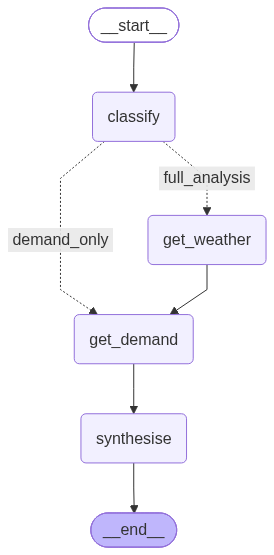

In [33]:
# Draw the workflow graph so the LangGraph control flow is visible.
if LG_AVAILABLE:
    from IPython.display import Image, display
    display(Image(lg_app.get_graph().draw_mermaid_png()))

In [31]:
STORE_QUERY

"I am the store manager at WMT-2847 in Bengaluru. Based on today's actual weather conditions and current market demand signals, give me 3 specific product categories I should prioritise stocking today. For each category, explain why the live data supports this recommendation."

In [34]:
# Summarise the trade-offs of the three framework options in one table.
FRAMEWORK_TCO = {
    'Python-only': {
        'loc_simple':        30,
        'loc_multi_agent':  400,
        'ext_dependencies':   1,
        'debugging':        'Low (standard Python stack)',
        'multi_agent':      'Manual scaffolding required',
        'observability':    'Manual (print / logging)',
        'learning_curve_d':   0,
        'version_risk':     'None (no framework dependency)',
        'best_for':         'Prototypes, single-step cost-sensitive pipelines',
        'latency_sec':      py_result['latency_sec'],
    },
    'LangChain': {
        'loc_simple':        15,
        'loc_multi_agent':  180,
        'ext_dependencies':   8,
        'debugging':        'Medium-High (abstraction layers)',
        'multi_agent':      'Partial (AgentExecutor)',
        'observability':    'LangSmith (requires account)',
        'learning_curve_d':   3,
        'version_risk':     'High (frequent breaking changes)',
        'best_for':         'RAG pipelines, single-agent tools, rapid prototyping',
        'latency_sec':      round(lc_latency, 2) if lc_latency else 'N/A',
    },
    'LangGraph': {
        'loc_simple':        50,
        'loc_multi_agent':  130,
        'ext_dependencies':   5,
        'debugging':        'Medium (explicit state, step-by-step)',
        'multi_agent':      'First-class (graph-native StateGraph)',
        'observability':    'LangSmith + checkpointing',
        'learning_curve_d':   5,
        'version_risk':     'Medium (stable since v0.2)',
        'best_for':         'Multi-agent systems, human-in-the-loop, complex workflows',
        'latency_sec':      round(lg_latency, 2) if lg_latency else 'N/A',
    },
}

headers = ['Metric'] + list(FRAMEWORK_TCO.keys())
print(f'{headers[0]:<38} {headers[1]:>16} {headers[2]:>16} {headers[3]:>16}')
print('-' * 88)

metrics = [
    'loc_simple', 'loc_multi_agent', 'ext_dependencies',
    'debugging', 'multi_agent', 'learning_curve_d', 'version_risk', 'latency_sec',
]
for m in metrics:
    vals = [str(FRAMEWORK_TCO[fw][m]) for fw in FRAMEWORK_TCO]
    print(f'{m:<38} {vals[0]:>16} {vals[1]:>16} {vals[2]:>16}')

print()
for fw, data in FRAMEWORK_TCO.items():
    print(f'{fw}: {data["best_for"]}')

Metric                                      Python-only        LangChain        LangGraph
----------------------------------------------------------------------------------------
loc_simple                                           30               15               50
loc_multi_agent                                     400              180              130
ext_dependencies                                      1                8                5
debugging                              Low (standard Python stack) Medium-High (abstraction layers) Medium (explicit state, step-by-step)
multi_agent                            Manual scaffolding required Partial (AgentExecutor) First-class (graph-native StateGraph)
learning_curve_d                                      0                3                5
version_risk                           None (no framework dependency) High (frequent breaking changes) Medium (stable since v0.2)
latency_sec                                        2.86         

## Section 4: Build vs Buy Rubric

Build vs Buy is the decision that precedes framework selection.
If the answer is Buy, you are evaluating vendors, not frameworks.

The rubric scores five axes (each 1-3):
- **Differentiation:** Does this component create competitive advantage?
- **Complexity:** How hard is it to build and maintain at scale?
- **Vendor risk:** How much lock-in does buying create?
- **Speed to value:** How fast does buy vs build deliver the first working version?
- **Cost advantage:** Is build cost (engineering time) lower or higher than buy cost (licensing + integration)?

Score >= 11 = **Build** | Score <= 8 = **Buy** | 9-10 = **Buy + Customize**

In [35]:
# Score each platform decision with the same simple rubric.
# This makes the Build vs Buy choice more explicit and repeatable.
def build_or_buy(component: str, scores: dict) -> dict:
    # scores: each axis is 1=Buy-favoured, 2=Neutral, 3=Build-favoured
    total = sum(scores.values())
    if total >= 11:
        decision  = 'BUILD'
        rationale = 'Component creates differentiation or vendor risk is too high to accept'
    elif total <= 8:
        decision  = 'BUY'
        rationale = 'Commodity capability; vendor delivers faster and cheaper'
    else:
        decision  = 'BUY + CUSTOMIZE'
        rationale = 'Start with vendor solution, extend where differentiation matters'
    return {
        'component': component, 'scores': scores,
        'total': total, 'decision': decision, 'rationale': rationale,
    }

components = [
    ('Orchestration framework (LangGraph)', {
        'differentiation': 1, 'complexity': 2,
        'vendor_risk': 2,     'speed_advantage': 3, 'cost_advantage': 1,
    }),
    ('RAG vector store (Chroma vs Pinecone)', {
        'differentiation': 1, 'complexity': 3,
        'vendor_risk': 1,     'speed_advantage': 1, 'cost_advantage': 2,
    }),
    ('Walmart domain knowledge base (Q&A dataset)', {
        'differentiation': 3, 'complexity': 1,
        'vendor_risk': 3,     'speed_advantage': 1, 'cost_advantage': 3,
    }),
    ('LLM inference (OpenAI API vs self-hosted)', {
        'differentiation': 1, 'complexity': 3,
        'vendor_risk': 2,     'speed_advantage': 1, 'cost_advantage': 1,
    }),
    ('MCP tool server (FastMCP vs custom HTTP)', {
        'differentiation': 1, 'complexity': 2,
        'vendor_risk': 1,     'speed_advantage': 3, 'cost_advantage': 2,
    }),
]

results = [build_or_buy(name, scores) for name, scores in components]

print(f'{"Component":<48} {"Score":>6} {"Decision":>18}')
print('-' * 74)
for r in results:
    print(f'{r["component"]:<48} {r["total"]:>6} {r["decision"]:>18}')

print()
for r in results:
    print(f'{r["component"]}:')
    print(f'  {r["decision"]}: {r["rationale"]}')

Component                                         Score           Decision
--------------------------------------------------------------------------
Orchestration framework (LangGraph)                   9    BUY + CUSTOMIZE
RAG vector store (Chroma vs Pinecone)                 8                BUY
Walmart domain knowledge base (Q&A dataset)          11              BUILD
LLM inference (OpenAI API vs self-hosted)             8                BUY
MCP tool server (FastMCP vs custom HTTP)              9    BUY + CUSTOMIZE

Orchestration framework (LangGraph):
  BUY + CUSTOMIZE: Start with vendor solution, extend where differentiation matters
RAG vector store (Chroma vs Pinecone):
  BUY: Commodity capability; vendor delivers faster and cheaper
Walmart domain knowledge base (Q&A dataset):
  BUILD: Component creates differentiation or vendor risk is too high to accept
LLM inference (OpenAI API vs self-hosted):
  BUY: Commodity capability; vendor delivers faster and cheaper
MCP tool server (F

## Summary

You have built and compared production-grade AI protocol and framework implementations using **live external data**:

- **Protocol:** REST vs MCP -- both called real OpenWeatherMap and Tavily APIs. MCP wins for multi-agent reuse at Walmart scale because tool schemas live on the server, not in every agent's code.
- **Framework:** All three frameworks fetched real weather and real demand signals and produced grounded recommendations from live data. LangGraph's explicit typed state is the right choice for the Walmart Retail Assistant's multi-step workflow.
- **Build vs Buy:** Quantified per component. Domain knowledge base is always BUILD. Everything else is BUY or BUY+CUSTOMIZE using open-source tools.

**Key principle:** These decisions compound. Wrong protocol forces a framework rewrite. Wrong Build vs Buy wastes 3-6 months of engineering. Score the rubric before writing a single line of production code.

**Your deliverable:** `framework_selection_matrix.txt` -- ARB-ready with live latency and cost data from this session.

**Next:** IN04 -- Agent Design Principles